# Étape 4 — Les grecques par Monte Carlo

Les grecques sont les **sensibilités** du prix aux paramètres :

$$\Delta = \frac{\partial C}{\partial S_0}, \qquad \Gamma = \frac{\partial^2 C}{\partial S_0^2}, \qquad \mathcal V = \frac{\partial C}{\partial \sigma}$$

Le prix est une espérance $C(\theta) = \mathbb E\big[e^{-rT}h(S_T(\theta))\big]$, qu'on ne connaît qu'à travers une estimation bruitée. Comment estimer sa **dérivée** ? Trois familles de méthodes :

1. **Différences finies** (*bump and reprice*) : on reprice avec un paramètre décalé.
2. **Méthode trajectorielle** (*pathwise*) : on dérive le payoff à l'intérieur de l'espérance.
3. **Rapport de vraisemblance** (*likelihood ratio*) : on dérive la densité de $S_T$.

Plan :
- validation sur le call européen contre les grecques fermées de Black-Scholes ;
- choix du pas $h$ et rôle des nombres aléatoires communs ;
- comparaison des trois méthodes à budget égal ;
- limite de la méthode trajectorielle sur l'option digitale ;
- application au delta d'une asiatique arithmétique (sans formule fermée).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats import t as student

## 0. Briques de base

In [2]:
# Code : mcpricing/engine.py (summarize), mcpricing/simulation.py (terminal_prices)
# et mcpricing/closed_form.py (grecques fermées de Black-Scholes, prix et delta de la digitale)
from mcpricing.engine import summarize
from mcpricing.simulation import terminal_prices
from mcpricing.closed_form import (bs_call_price, bs_call_delta, bs_call_gamma, bs_call_vega,
                                   digital_price, digital_delta)


params = dict(S0=100.0, K=100.0, T=1.0, r=0.03, sigma=0.2)
S0, K, T, r, sigma = params.values()
disc = np.exp(-r * T)
exact = dict(delta=bs_call_delta(**params), gamma=bs_call_gamma(**params), vega=bs_call_vega(**params))
print(f"Call ATM : prix {bs_call_price(**params):.4f}, delta {exact['delta']:.5f}, "
      f"gamma {exact['gamma']:.6f}, vega {exact['vega']:.4f}")

Call ATM : prix 9.4134, delta 0.59871, gamma 0.019333, vega 38.6668


# 1. Différences finies

On reprice avec le paramètre décalé de $\pm h$ et on fait la différence **centrée** :

$$\hat\Delta_h = \frac{\hat C(S_0 + h) - \hat C(S_0 - h)}{2h}, \qquad \hat\Gamma_h = \frac{\hat C(S_0 + h) - 2\hat C(S_0) + \hat C(S_0 - h)}{h^2}$$

**Biais.** Par Taylor, $\frac{C(S_0+h) - C(S_0-h)}{2h} = \Delta + O(h^2)$ : le biais diminue quand $h$ diminue.

**Variance.** Tout dépend des nombres aléatoires utilisés pour les deux prix :
- **tirages indépendants** : $\operatorname{Var}(\hat\Delta_h) = \frac{\operatorname{Var}(\hat C_+) + \operatorname{Var}(\hat C_-)}{4h^2} \approx \frac{\sigma_Y^2}{2Nh^2}$, qui **explose** quand $h \to 0$ ;
- **nombres aléatoires communs** (mêmes $Z$ pour les deux prix) : les deux payoffs sont très proches trajectoire par trajectoire, leur différence est d'ordre $h$, et la variance reste d'ordre $\frac1N$ (pour un payoff continu).

**Le compromis :** $h$ petit réduit le biais, mais sans aléas communs, il fait exploser la variance. Avec les aléas communs, on peut prendre $h$ petit sans payer en variance.

In [3]:
# Code : mcpricing/greeks.py (fd_delta, fd_gamma, fd_vega) et mcpricing/payoffs.py (call_payoff)
from mcpricing.greeks import fd_delta, fd_gamma, fd_vega
from mcpricing.payoffs import call_payoff

N = 500_000

## 1.1 Le choix de $h$ : aléas indépendants contre aléas communs

Delta exact : 0.59871

     h   Indépendants      ± SE    Communs      ± SE
  0.01        0.38875   1.41111    0.59837   0.00083
   0.1        0.57771   0.14111    0.59834   0.00083
   0.5        0.59443   0.02823    0.59823   0.00082


   1.0        0.59640   0.01412    0.59812   0.00082
   2.0        0.59717   0.00707    0.59783   0.00081
   5.0        0.59634   0.00285    0.59633   0.00079
  10.0        0.59155   0.00147    0.59136   0.00075


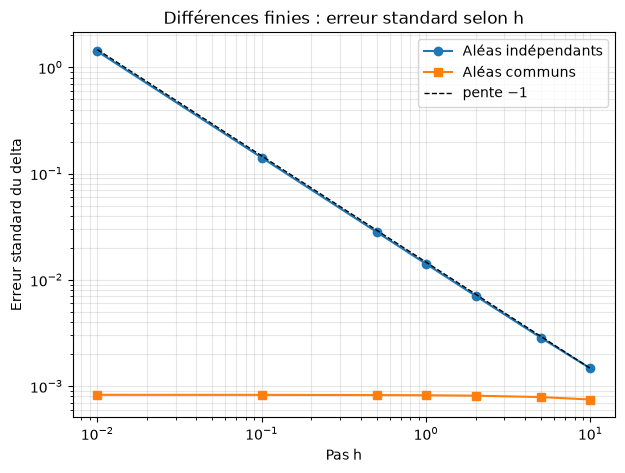

In [4]:
h_list = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
se_ind, se_crn = [], []
print(f"Delta exact : {exact['delta']:.5f}\n")
print(f"{'h':>6} {'Indépendants':>14} {'± SE':>9} {'Communs':>10} {'± SE':>9}")
for h in h_list:
    d_i, s_i, _ = fd_delta(call_payoff, **params, h=h, n_paths=N, seed=42, common=False)
    d_c, s_c, _ = fd_delta(call_payoff, **params, h=h, n_paths=N, seed=42, common=True)
    se_ind.append(s_i); se_crn.append(s_c)
    print(f"{h:>6} {d_i:>14.5f} {s_i:>9.5f} {d_c:>10.5f} {s_c:>9.5f}")

plt.figure(figsize=(7, 5))
plt.loglog(h_list, se_ind, "o-", label="Aléas indépendants")
plt.loglog(h_list, se_crn, "s-", label="Aléas communs")
plt.loglog(h_list, se_ind[-1] * (h_list[-1] / np.array(h_list)), "k--", lw=1, label=r"pente $-1$")
plt.xlabel("Pas h")
plt.ylabel("Erreur standard du delta")
plt.title("Différences finies : erreur standard selon h")
plt.legend(); plt.grid(True, which="both", alpha=0.3)
plt.show()

Avec des aléas **indépendants**, l'erreur standard est proportionnelle à $\frac1h$ : pour $h = 0{,}01$, le delta estimé est inutilisable. Avec des aléas **communs**, elle ne dépend presque plus de $h$. Le biais en $O(h^2)$ n'apparaît que pour les grands $h$.

## 1.2 Gamma et vega par différences finies

In [5]:
print(f"Gamma exact : {exact['gamma']:.6f}")
for h in [0.1, 1.0, 5.0]:
    g, s, _ = fd_gamma(call_payoff, **params, h=h, n_paths=N, seed=42)
    print(f"  h = {h:>4} : {g:.6f} ± {s:.6f}")
print(f"\nVega exact : {exact['vega']:.4f}")
for h in [0.001, 0.01, 0.05]:
    v, s, _ = fd_vega(call_payoff, **params, h=h, n_paths=N, seed=42)
    print(f"  h = {h:>5} : {v:.4f} ± {s:.4f}")

Gamma exact : 0.019333
  h =  0.1 : 0.019609 ± 0.000503
  h =  1.0 : 0.019365 ± 0.000156
  h =  5.0 : 0.019282 ± 0.000065

Vega exact : 38.6668
  h = 0.001 : 38.6937 ± 0.1063
  h =  0.01 : 38.6939 ± 0.1063
  h =  0.05 : 38.6659 ± 0.1063


Pour le **gamma**, même avec des aléas communs, l'erreur standard **augmente quand $h$ diminue** : le payoff du call a un coude en $K$, donc sa dérivée seconde n'existe pas trajectoire par trajectoire, et la différence seconde n'est non nulle que pour les trajectoires qui finissent près du strike. C'est la grecque la plus difficile à estimer.

# 2. Méthode trajectorielle (*pathwise*)

On dérive **à l'intérieur** de l'espérance, trajectoire par trajectoire (ce qui demande un payoff assez régulier pour échanger dérivée et espérance) :

$$\frac{\partial}{\partial\theta}\,\mathbb E\big[e^{-rT}h(S_T)\big] = \mathbb E\left[e^{-rT}\,h'(S_T)\,\frac{\partial S_T}{\partial \theta}\right]$$

Avec $S_T = S_0\exp\big((r - \frac{\sigma^2}{2})T + \sigma\sqrt T\,Z\big)$ :

$$\frac{\partial S_T}{\partial S_0} = \frac{S_T}{S_0}, \qquad \frac{\partial S_T}{\partial \sigma} = S_T\,\big(-\sigma T + \sqrt T\,Z\big)$$

Pour le call, $h'(s) = \mathbf 1_{\{s > K\}}$ (presque partout) :

$$\Delta = \mathbb E\left[e^{-rT}\,\mathbf 1_{\{S_T > K\}}\,\frac{S_T}{S_0}\right], \qquad \mathcal V = \mathbb E\Big[e^{-rT}\,\mathbf 1_{\{S_T > K\}}\,S_T\big(-\sigma T + \sqrt T Z\big)\Big]$$

**Gamma : échec.** La dérivée de $\mathbf 1_{\{S_T > K\}}$ est nulle presque partout : l'estimateur trajectoriel du gamma vaut **zéro**, alors que le vrai gamma est positif. La dérivée de l'indicatrice est un Dirac en $K$, invisible tirage par tirage.

In [6]:
# Code : mcpricing/greeks.py (pathwise_greeks : delta, gamma = 0 et vega trajectoriels du call)
from mcpricing.greeks import pathwise_greeks


pw = pathwise_greeks(**params, n_paths=N, seed=42)
for g in ["delta", "gamma", "vega"]:
    est, se, _ = pw[g]
    print(f"{g:>6} : {est:.6f} ± {se:.6f}   (exact {exact[g]:.6f})")

 delta : 0.598382 ± 0.000828   (exact 0.598706)
 gamma : 0.000000 ± 0.000000   (exact 0.019333)
  vega : 38.693261 ± 0.106267   (exact 38.666812)


# 3. Rapport de vraisemblance (*likelihood ratio*)

On écrit le prix comme une intégrale contre la **densité** $f(s;\theta)$ de $S_T$, et on dérive la densité au lieu du payoff :

$$\frac{\partial}{\partial\theta}\int e^{-rT}h(s)\,f(s;\theta)\,ds = \int e^{-rT}h(s)\,\frac{\partial_\theta f(s;\theta)}{f(s;\theta)}\,f(s;\theta)\,ds = \mathbb E\Big[e^{-rT}h(S_T)\;\underbrace{\partial_\theta \ln f(S_T;\theta)}_{\text{score}}\Big]$$

Le payoff n'est **jamais dérivé** : la méthode marche pour n'importe quel payoff, même discontinu. Comme $\ln S_T \sim \mathcal N\big(\ln S_0 + (r - \frac{\sigma^2}{2})T,\ \sigma^2 T\big)$, les scores s'écrivent avec $Z$ :

$$\text{Delta : } \frac{Z}{S_0\,\sigma\sqrt T}, \qquad \text{Gamma : } \frac{Z^2 - 1}{S_0^2\,\sigma^2 T} - \frac{Z}{S_0^2\,\sigma\sqrt T}, \qquad \text{Vega : } \frac{Z^2 - 1}{\sigma} - Z\sqrt T$$

**Contrepartie :** les poids (score) peuvent être grands et multiplient le payoff entier, d'où une **variance plus élevée** que la méthode trajectorielle.

In [7]:
# Code : mcpricing/greeks.py (lr_greeks : delta, gamma et vega par rapport de vraisemblance)
from mcpricing.greeks import lr_greeks


lr = lr_greeks(call_payoff, **params, n_paths=N, seed=42)
for g in ["delta", "gamma", "vega"]:
    est, se, _ = lr[g]
    print(f"{g:>6} : {est:.6f} ± {se:.6f}   (exact {exact[g]:.6f})")

 delta : 0.600041 ± 0.002017   (exact 0.598706)
 gamma : 0.019596 ± 0.000195   (exact 0.019333)
  vega : 39.192019 ± 0.389009   (exact 38.666812)


## 3.1 Le meilleur des deux mondes : gamma mixte

On applique la méthode trajectorielle **une fois** (pour obtenir le delta, régulier), puis le rapport de vraisemblance **une fois** (pour dériver ce delta) :

$$\Gamma = \frac{\partial}{\partial S_0}\,\mathbb E\left[e^{-rT}\mathbf 1_{\{S_T>K\}}\frac{S_T}{S_0}\right] = \mathbb E\left[e^{-rT}\,\mathbf 1_{\{S_T>K\}}\,\frac{S_T}{S_0^2}\left(\frac{Z}{\sigma\sqrt T} - 1\right)\right]$$

(le $-1$ vient de la dérivée de $\frac{1}{S_0}$, le $\frac{Z}{\sigma\sqrt T}$ du score). On évite à la fois la dérivée du coude et les gros poids du rapport de vraisemblance pur.

In [8]:
# Code : mcpricing/greeks.py (mixed_gamma)
from mcpricing.greeks import mixed_gamma


est, se, _ = mixed_gamma(**params, n_paths=N, seed=42)
print(f"Gamma mixte : {est:.6f} ± {se:.6f}   (exact {exact['gamma']:.6f})")

Gamma mixte : 0.019347 ± 0.000053   (exact 0.019333)


# 4. Comparaison à budget égal

Même nombre de trajectoires $N = 500\,000$ pour chaque méthode. Pour les différences finies : aléas communs, $h = 1$ pour le delta et le gamma, $h = 0{,}01$ pour le vega. Le **rapport de variance** est $\mathrm{Var}_{\text{méthode}} / \mathrm{Var}_{\text{trajectorielle}}$ (plus il est grand, plus la méthode est bruitée).

In [9]:
fd = {"delta": fd_delta(call_payoff, **params, h=1.0, n_paths=N, seed=42),
      "gamma": fd_gamma(call_payoff, **params, h=1.0, n_paths=N, seed=42),
      "vega": fd_vega(call_payoff, **params, h=0.01, n_paths=N, seed=42)}
mixed = mixed_gamma(**params, n_paths=N, seed=42)

rows = [("Delta", "delta"), ("Gamma", "gamma"), ("Vega", "vega")]
print(f"{'Grecque':<7} {'Exact':>10} | {'Diff. finies':>20} | {'Trajectorielle':>20} | {'Vraisemblance':>20}")
for name, g in rows:
    cells_ = []
    for res in [fd[g], pw[g] if g != "gamma" else mixed, lr[g]]:
        cells_.append(f"{res[0]:>10.5f} ± {res[1]:.5f}")
    print(f"{name:<7} {exact[g]:>10.5f} | " + " | ".join(f"{c:>20}" for c in cells_))
print("(Gamma, colonne trajectorielle : estimateur mixte, la méthode trajectorielle pure donnant 0.)")

print("\nRapport de variance par rapport à la méthode trajectorielle (delta, vega) :")
for name, g in [("Delta", "delta"), ("Vega", "vega")]:
    print(f"  {name} : diff. finies {fd[g][1]**2 / pw[g][1]**2:.2f}, vraisemblance {lr[g][1]**2 / pw[g][1]**2:.2f}")

Grecque      Exact |         Diff. finies |       Trajectorielle |        Vraisemblance
Delta      0.59871 |    0.59812 ± 0.00082 |    0.59838 ± 0.00083 |    0.60004 ± 0.00202
Gamma      0.01933 |    0.01937 ± 0.00016 |    0.01935 ± 0.00005 |    0.01960 ± 0.00019
Vega      38.66681 |   38.69389 ± 0.10626 |   38.69326 ± 0.10627 |   39.19202 ± 0.38901
(Gamma, colonne trajectorielle : estimateur mixte, la méthode trajectorielle pure donnant 0.)

Rapport de variance par rapport à la méthode trajectorielle (delta, vega) :


  Delta : diff. finies 0.98, vraisemblance 5.93
  Vega : diff. finies 1.00, vraisemblance 13.40


**À retenir :** pour un payoff continu comme le call, la méthode **trajectorielle** est la plus précise pour le delta et le vega, sans aucun repricing. Le **rapport de vraisemblance** est sans biais mais nettement plus bruité. Les **différences finies** avec aléas communs font presque aussi bien que la trajectorielle, au prix d'un biais en $O(h^2)$ et de deux repricings par grecque.

# 5. La limite de la méthode trajectorielle : l'option digitale

Une digitale *cash-or-nothing* paie $1$ si $S_T > K$, et $0$ sinon. Son delta exact vaut

$$\Delta_{\text{dig}} = \frac{e^{-rT}\,\varphi(d_-)}{S_0\,\sigma\sqrt T}$$

- **Trajectorielle :** le payoff est constant de part et d'autre de $K$, donc sa dérivée est nulle presque partout. L'estimateur vaut **zéro** : la méthode est fausse.
- **Rapport de vraisemblance :** le payoff n'est pas dérivé, la méthode marche sans changement.
- **Différences finies :** elles marchent, mais la différence n'est non nulle que pour les trajectoires qui traversent $K$ entre $S_0 - h$ et $S_0 + h$ : la variance explose quand $h \to 0$.

(Remarque : avec $K = S_0$, ce delta coïncide numériquement avec le gamma du call, par l'identité $S_0\,\varphi(d_+) = Ke^{-rT}\varphi(d_-)$.)

In [10]:
# Code : mcpricing/payoffs.py (digital_payoff : 1 si S_T > K)
from mcpricing.payoffs import digital_payoff

dig_exact = digital_delta(**params)

Z = np.random.default_rng(42).standard_normal(N)
ST = terminal_prices(S0, T, r, sigma, Z)
pw_dig = summarize(np.zeros(N))                                   # dérivée de l'indicatrice : 0
lr_dig = summarize(disc * digital_payoff(ST, K) * Z / (S0 * sigma * np.sqrt(T)))

print(f"Delta digitale exact : {dig_exact:.6f}\n")
print(f"{'Méthode':<28} {'Estimation':>11} {'± SE':>10}")
print(f"{'Trajectorielle':<28} {pw_dig[0]:>11.6f} {pw_dig[1]:>10.6f}")
print(f"{'Rapport de vraisemblance':<28} {lr_dig[0]:>11.6f} {lr_dig[1]:>10.6f}")
for h in [0.01, 0.5, 2.0]:
    d = fd_delta(digital_payoff, **params, h=h, n_paths=N, seed=42)
    print(f"{f'Diff. finies (h = {h})':<28} {d[0]:>11.6f} {d[1]:>10.6f}")

Delta digitale exact : 0.019333

Méthode                       Estimation       ± SE
Trajectorielle                  0.000000   0.000000
Rapport de vraisemblance        0.019330   0.000040


Diff. finies (h = 0.01)         0.019215   0.001365


Diff. finies (h = 0.5)          0.019413   0.000192
Diff. finies (h = 2.0)          0.019267   0.000093


# 6. Application : le delta d'une asiatique arithmétique

Pas de formule fermée : on vérifie que les trois méthodes donnent **la même valeur**. Trajectoire à $n = 12$ dates, $S_{t_k} = S_0\exp(\dots)$, donc $\frac{\partial S_{t_k}}{\partial S_0} = \frac{S_{t_k}}{S_0}$ et $\frac{\partial A_n}{\partial S_0} = \frac{A_n}{S_0}$.

- **Trajectorielle :** $\Delta = \mathbb E\big[e^{-rT}\mathbf 1_{\{A_n > K\}}\frac{A_n}{S_0}\big]$.
- **Rapport de vraisemblance :** $S_0$ n'intervient que dans la loi du premier pas, d'où le poids $\frac{Z_1}{S_0\,\sigma\sqrt{\Delta t}}$.
- **Différences finies :** aléas communs, $h = 0{,}5$.

In [11]:
# Code : mcpricing/greeks.py (asian_call_delta : les trois méthodes sur les mêmes accroissements gaussiens)
from mcpricing.greeks import asian_call_delta


n_dates, N_asian, h = 12, 200_000, 0.5
asian = asian_call_delta(**params, n_dates=n_dates, n_paths=N_asian, h=h, seed=7)
pw_a, lr_a, fd_a = asian["pathwise"], asian["lr"], asian["fd"]

print(f"Delta de l'asiatique arithmétique (n = {n_dates}, N = {N_asian})\n")
for name, res in [("Trajectorielle", pw_a), ("Rapport de vraisemblance", lr_a), ("Diff. finies (h = 0,5)", fd_a)]:
    print(f"{name:<26} {res[0]:.5f} ± {res[1]:.5f}")

Delta de l'asiatique arithmétique (n = 12, N = 200000)

Trajectorielle             0.56430 ± 0.00121
Rapport de vraisemblance   0.56660 ± 0.00450
Diff. finies (h = 0,5)     0.56411 ± 0.00120


Les trois méthodes concordent. Le rapport de vraisemblance est encore le plus bruité, d'autant plus que son poids $\frac{Z_1}{S_0\sigma\sqrt{\Delta t}}$ grandit quand le pas $\Delta t$ diminue.

# Bilan de l'étape 4

| | Différences finies | Trajectorielle | Rapport de vraisemblance |
|---|---|---|---|
| Principe | reprice avec paramètre décalé | dérive le payoff | dérive la densité |
| Biais | $O(h^2)$ | aucun | aucun |
| Variance | faible avec aléas communs | la plus faible | élevée |
| Payoff discontinu (digitale) | oui, mais bruité | **non** | oui |
| Gamma du call | bruité | **non** (vaut 0) | oui ; mieux : estimateur mixte |
| Coût | 2 ou 3 repricings par grecque | aucun repricing | aucun repricing |

**Règle pratique :** méthode trajectorielle pour les payoffs réguliers ; rapport de vraisemblance (ou estimateur mixte) dès que le payoff est discontinu ou pour le gamma ; différences finies avec aléas communs comme méthode universelle de contrôle.